In [3]:
import pandas as pd
import numpy as np
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.base import clone

nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and len(token) > 2
    ]
    return " ".join(tokens)

train_df = pd.read_csv("DBLPTrainset.txt", sep="\t", header=None, names=["Label", "Title"])
test_df = pd.read_csv("DBLPTestset.txt", sep="\t", header=None, names=["Title"])
test_truth = pd.read_csv("DBLPTestGroundTruth.txt", sep="\t", header=None, names=["Label"])

train_df["Cleaned_Title"] = train_df["Title"].apply(preprocess)
test_df["Cleaned_Title"] = test_df["Title"].apply(preprocess)

y_train = train_df["Label"]
y_test = test_truth["Label"]

In [4]:
# ----------------------------
# Evaluation function with full cross-validation
# ----------------------------
def evaluate_model(X, y, name, model, k=5):
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    precisions, recalls, f1s = [], [], []
    all_true, all_pred = [], []

    for train_idx, test_idx in cv.split(X, y):
        X_tr, X_val = X[train_idx], X[test_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[test_idx]

        clf = clone(model)
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)

        all_true.extend(y_val)
        all_pred.extend(y_pred)

        precisions.append(precision_score(y_val, y_pred, average="micro", zero_division=0))
        recalls.append(recall_score(y_val, y_pred, average="micro", zero_division=0))
        f1s.append(f1_score(y_val, y_pred, average="micro", zero_division=0))

    print(f"\n=== {name} ===")
    print(f"Precision (micro): {np.mean(precisions):.4f}")
    print(f"Recall (micro):    {np.mean(recalls):.4f}")
    print(f"F1-score (micro):  {np.mean(f1s):.4f}")
    print("Confusion Matrix (aggregated):")
    print(confusion_matrix(all_true, all_pred))

    return {
        'Combination': name,
        'Precision': np.mean(precisions),
        'Recall': np.mean(recalls),
        'F1': np.mean(f1s)
    }

In [5]:
# ----------------------------
# Pipeline components
# ----------------------------
vectorizers = {
    "TF-IDF": TfidfVectorizer(
        max_features=5000, ngram_range=(1, 2), stop_words='english', min_df=3, max_df=0.85),
    "CountVectorizer": CountVectorizer(
        max_features=5000, ngram_range=(1, 2), stop_words='english', min_df=3, max_df=0.85)
}

reducers = {
    "None": None,
    "TruncatedSVD": TruncatedSVD(n_components=300, random_state=42),
    "PCA": "PCA",  # handled specially
    "Chi2": SelectKBest(chi2, k=300)
}

classifiers = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "LinearSVM": LinearSVC(),
    "RandomForest": RandomForestClassifier(),
    "MultinomialNB": MultinomialNB()
}

In [6]:
# ----------------------------
# Run combinations
# ----------------------------
results = []

for vec_name, vectorizer in vectorizers.items():
    print(f"\n[Vectorizer] {vec_name}")
    X_vec = vectorizer.fit_transform(train_df["Cleaned_Title"])

    for red_name, reducer in reducers.items():
        print(f"  [Reducer] {red_name}")

        if red_name == "PCA":
            X_red = PCA(n_components=300, random_state=42).fit_transform(X_vec.toarray())
        elif reducer is None:
            X_red = X_vec
        else:
            X_red = reducer.fit_transform(X_vec, y_train)

        for clf_name, clf in classifiers.items():
            if clf_name == "MultinomialNB" and red_name != "None":
                continue  # Naive Bayes only works without reduction

            combo_name = f"{vec_name} + {red_name} + {clf_name}"
            print(f"    [Classifier] {clf_name} → Evaluating: {combo_name}")
            result = evaluate_model(X_red, y_train, combo_name, clf)
            results.append(result)

# ----------------------------
# Results summary
# ----------------------------
results_df = pd.DataFrame(results)
sorted_results = results_df.sort_values(by="F1", ascending=False)

print("\n=== All Combinations Sorted by F1 Score ===\n")
for _, row in sorted_results.iterrows():
    print(f"{row['Combination']}")
    print(f"  Precision: {row['Precision']:.4f}")
    print(f"  Recall:    {row['Recall']:.4f}")
    print(f"  F1 Score:  {row['F1']:.4f}")
    print("-" * 40)


[Vectorizer] TF-IDF
  [Reducer] None
    [Classifier] LogisticRegression → Evaluating: TF-IDF + None + LogisticRegression

=== TF-IDF + None + LogisticRegression ===
Precision (micro): 0.8610
Recall (micro):    0.8610
F1-score (micro):  0.8610
Confusion Matrix (aggregated):
[[3934  268   36  110  133]
 [ 218 7090  122   48   36]
 [  38  297 2194   65   84]
 [ 133  193   67 2912  373]
 [ 201  133  107  346 2505]]
    [Classifier] LinearSVM → Evaluating: TF-IDF + None + LinearSVM


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_clas


=== TF-IDF + None + LinearSVM ===
Precision (micro): 0.8631
Recall (micro):    0.8631
F1-score (micro):  0.8631
Confusion Matrix (aggregated):
[[3953  195   48  127  158]
 [ 250 6984  158   67   55]
 [  46  198 2260   78   96]
 [ 142  118   91 2948  379]
 [ 210   80  122  346 2534]]
    [Classifier] RandomForest → Evaluating: TF-IDF + None + RandomForest


KeyboardInterrupt: 

In [17]:
import pandas as pd
import numpy as np
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# Load spaCy and define preprocessing
# ----------------------------
nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and len(token) > 2
    ]
    return " ".join(tokens)

# ----------------------------
# Load data
# ----------------------------
train_df = pd.read_csv("DBLPTrainset.txt", sep="\t", header=None, names=["Label", "Title"])
test_df = pd.read_csv("DBLPTestset.txt", sep="\t", header=None, names=["Title"])
test_truth = pd.read_csv("DBLPTestGroundTruth.txt", sep="\t", header=None, names=["Label"])
y_test = test_truth["Label"]

# ----------------------------
# Preprocess titles
# ----------------------------
train_df["Cleaned_Title"] = train_df["Title"].apply(preprocess)
test_df["Cleaned_Title"] = test_df["Title"].apply(preprocess)

y_train = train_df["Label"]
y_test = test_truth["Label"]

print("Class Distribution in Training Set:")
print(y_train.value_counts())
print("\nClass Distribution in Test Set:")
print(y_test.value_counts())

# ----------------------------
# Data Quality Checks: Duplicates and Missing Values
# ----------------------------

# Check for duplicate titles
train_dup_titles = train_df.duplicated(subset="Title").sum()
test_dup_titles = test_df.duplicated(subset="Title").sum()

# Check how many *unique* duplicated titles exist
unique_train_dup_titles = train_df[train_df.duplicated(subset="Title", keep=False)]["Title"].nunique()

# Show full-row duplicates (not just titles)
train_full_row_dups = train_df.duplicated().sum()
test_full_row_dups = test_df.duplicated().sum()

print("Train duplicate titles:", train_dup_titles)
print("Unique duplicate titles in train set:", unique_train_dup_titles)
print("Train full-row duplicates:", train_full_row_dups)
print("Test duplicate titles:", test_dup_titles)
print("Test full-row duplicates:", test_full_row_dups)

# Remove duplicates
train_df = train_df.drop_duplicates(subset="Title", keep="first")

# Check for missing values
print("\nMissing values in training set:")
print(train_df.isnull().sum())

print("\nMissing values in test set:")
print(test_df.isnull().sum())

print("\nMissing values in test ground truth:")
print(test_truth.isnull().sum())

# ----------------------------
# Outlier Detection (Title Length)
# ----------------------------
train_df["title_char_len"] = train_df["Title"].apply(len)
test_df["title_char_len"] = test_df["Title"].apply(len)

print("\nOutlier Check - Title Lengths:")
print("Training set → Min:", train_df["title_char_len"].min(), "| Max:", train_df["title_char_len"].max())
print("Test set     → Min:", test_df["title_char_len"].min(), "| Max:", test_df["title_char_len"].max())

# ----------------------------
# TF-IDF vectorization
# ----------------------------
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words='english',
    min_df=3,
    max_df=0.85
)

X_train = vectorizer.fit_transform(train_df["Cleaned_Title"])
X_test = vectorizer.transform(test_df["Cleaned_Title"])
y_train = train_df["Label"]

# Train final model
model = LinearSVC()
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)


# Evaluation
print("=== FINAL TEST SET EVALUATION ===\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
cm = confusion_matrix(y_test, y_pred)


Class Distribution in Training Set:
ISCAS       7514
INFOCOM     4481
VLDB        3678
WWW         3292
SIGGRAPH    2678
Name: Label, dtype: int64

Class Distribution in Test Set:
ISCAS       2043
INFOCOM      502
WWW          423
VLDB         219
SIGGRAPH     186
Name: Label, dtype: int64
Train duplicate titles: 146
Unique duplicate titles in train set: 121
Train full-row duplicates: 145
Test duplicate titles: 12
Test full-row duplicates: 12

Missing values in training set:
Label            0
Title            0
Cleaned_Title    0
dtype: int64

Missing values in test set:
Title            0
Cleaned_Title    0
dtype: int64

Missing values in test ground truth:
Label    0
dtype: int64

Outlier Check - Title Lengths:
Training set → Min: 5 | Max: 214
Test set     → Min: 10 | Max: 168


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


=== FINAL TEST SET EVALUATION ===

Classification Report:
              precision    recall  f1-score   support

     INFOCOM       0.77      0.76      0.77       502
       ISCAS       0.96      0.92      0.94      2043
    SIGGRAPH       0.69      0.81      0.74       186
        VLDB       0.56      0.79      0.66       219
         WWW       0.79      0.74      0.77       423

    accuracy                           0.86      3373
   macro avg       0.75      0.80      0.77      3373
weighted avg       0.87      0.86      0.86      3373



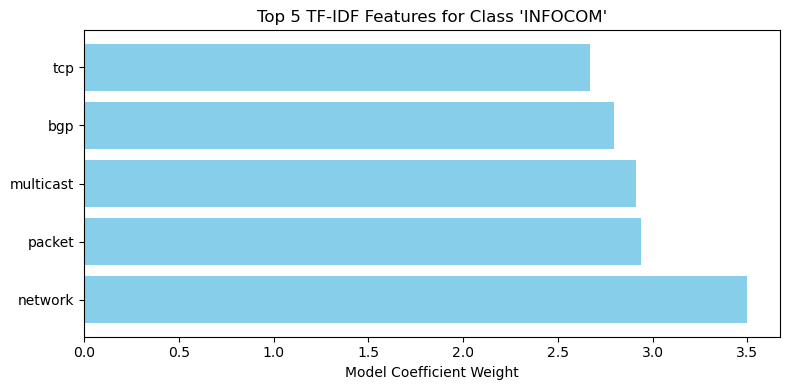

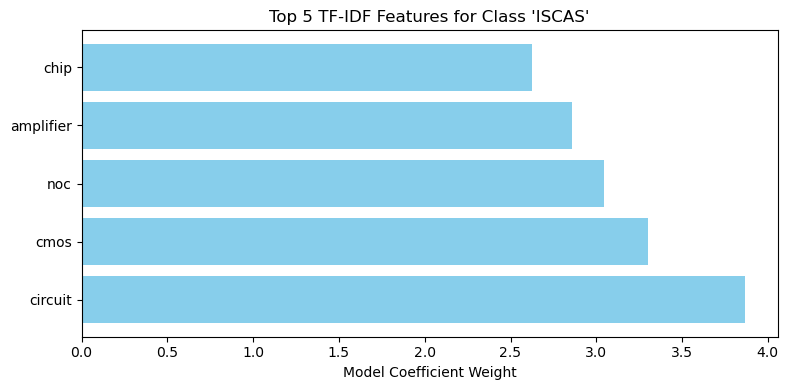

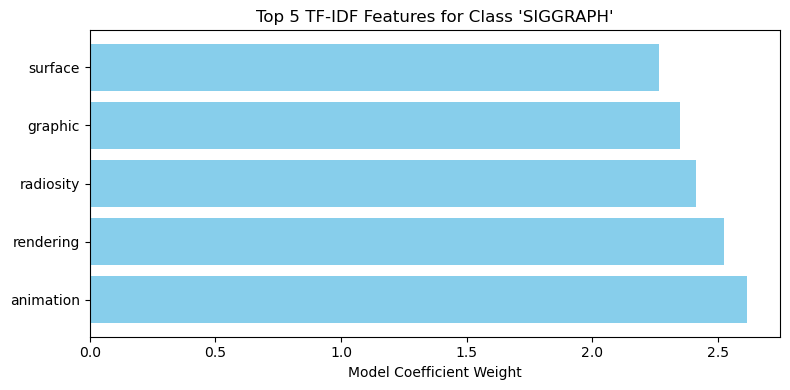

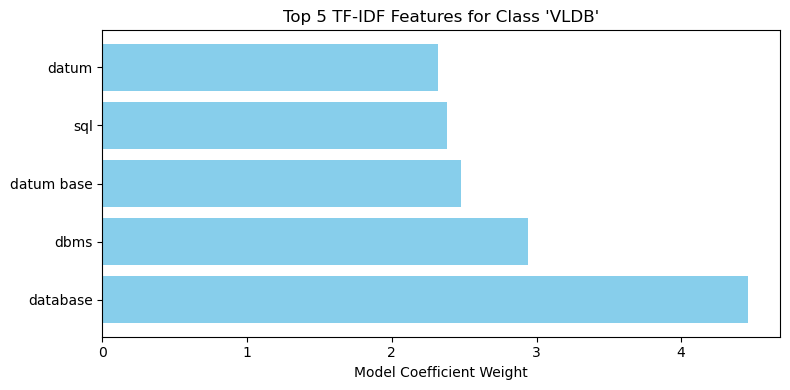

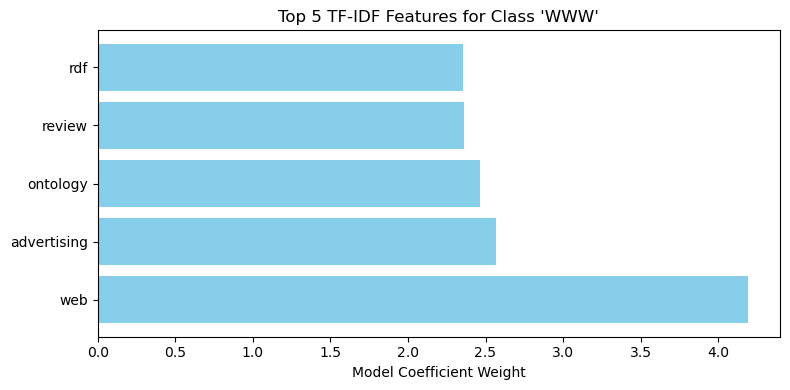

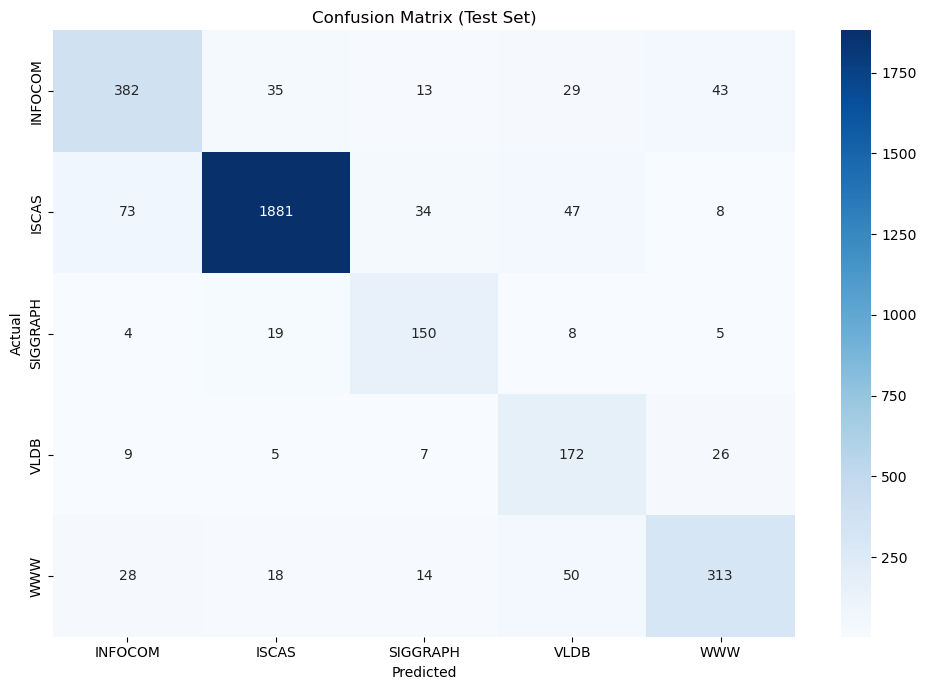

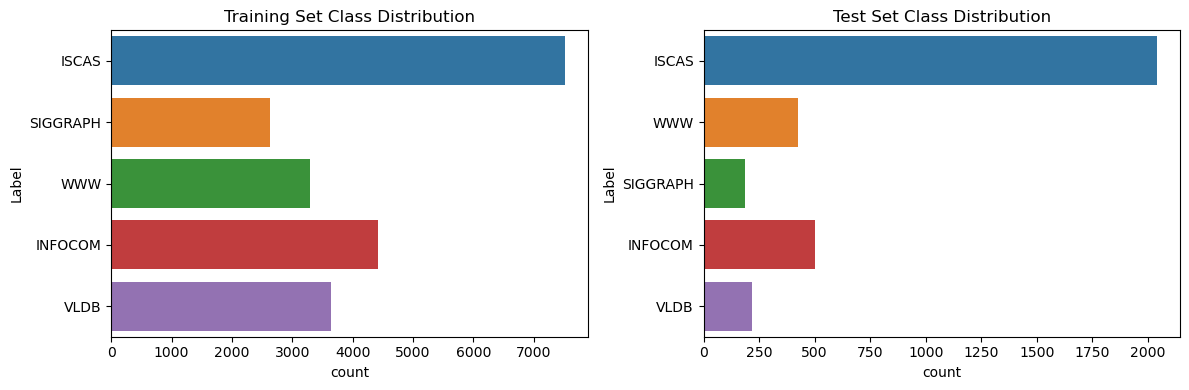

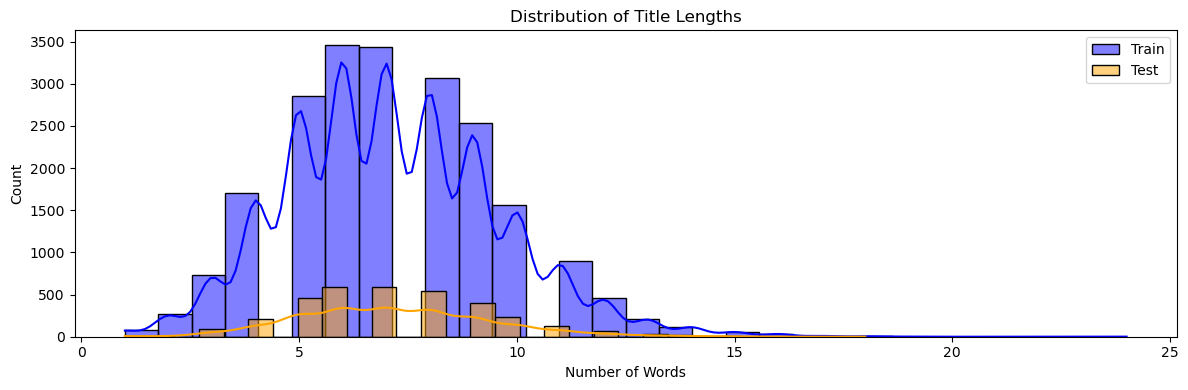


Top features for class 'INFOCOM':
  network
  packet
  multicast
  bgp
  tcp
  routing
  queue
  vehicular
  forwarding
  wireless

Top features for class 'ISCAS':
  circuit
  cmos
  noc
  amplifier
  chip
  fpga
  converter
  264
  voltage
  recognition

Top features for class 'SIGGRAPH':
  animation
  rendering
  radiosity
  graphic
  surface
  display
  art
  panel session
  ray
  dance

Top features for class 'VLDB':
  database
  dbms
  datum base
  sql
  datum
  join
  internet scale
  road network
  histogram
  oracle

Top features for class 'WWW':
  web
  advertising
  ontology
  review
  rdf
  xslt
  browser
  www
  topic
  link datum


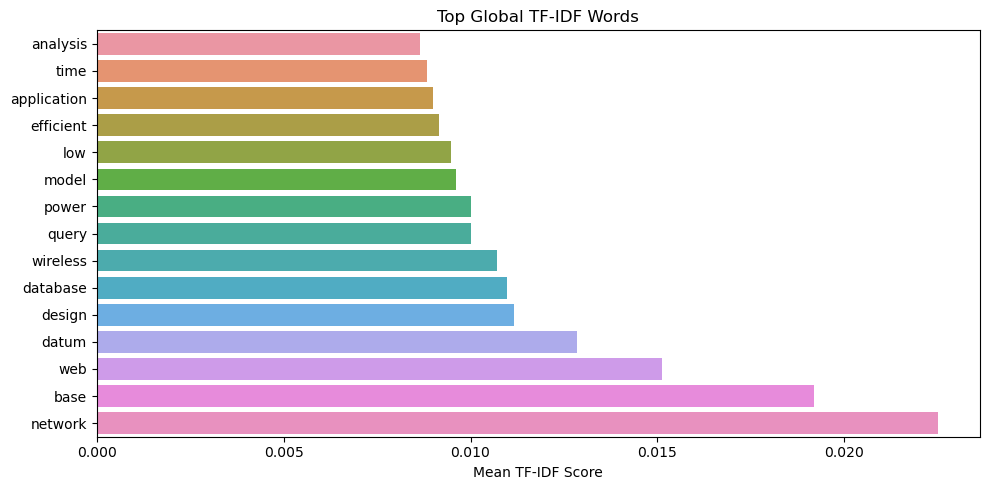

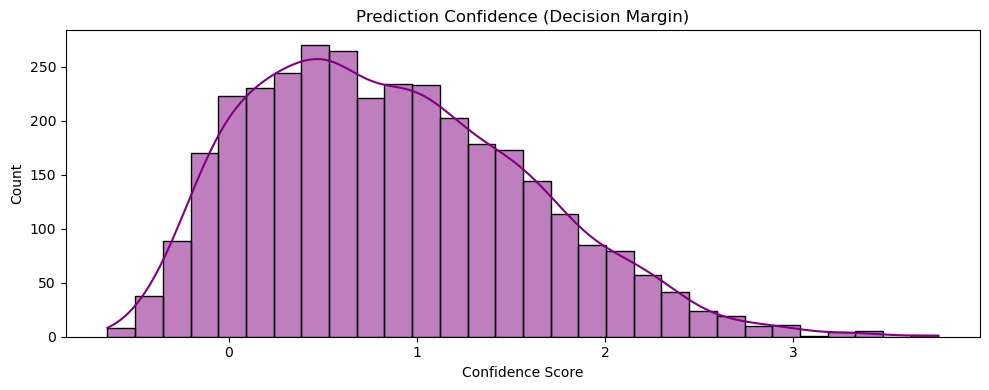

In [19]:
# ----------------------------
# Confusion Matrix Heatmap
# ----------------------------
def plot_conf_matrix(cm, labels):
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix (Test Set)")
    plt.tight_layout()
    plt.show()
# ----------------------------
# Class Distribution Plot
# ----------------------------
def plot_class_distribution(y_train, y_test):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(y=y_train, ax=axes[0])
    axes[0].set_title("Training Set Class Distribution")
    sns.countplot(y=y_test, ax=axes[1])
    axes[1].set_title("Test Set Class Distribution")
    plt.tight_layout()
    plt.show()

# ----------------------------
# Top TF-IDF Features Per Class
# ----------------------------
def plot_top_tfidf_features(vectorizer, model, class_labels, top_n=5):
    feature_names = np.array(vectorizer.get_feature_names_out())
    coefs = model.coef_

    for i, class_label in enumerate(class_labels):
        top_indices = np.argsort(coefs[i])[-top_n:]
        top_features = feature_names[top_indices]
        top_weights = coefs[i][top_indices]

        plt.figure(figsize=(8, 4))
        plt.barh(top_features, top_weights, color='skyblue')
        plt.title(f"Top {top_n} TF-IDF Features for Class '{class_label}'")
        plt.xlabel("Model Coefficient Weight")
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.show()

# ----------------------------
# 4. Length Distribution of Titles
# ----------------------------
def plot_title_lengths(train_df, test_df):
    train_lengths = train_df["Cleaned_Title"].apply(lambda x: len(x.split()))
    test_lengths = test_df["Cleaned_Title"].apply(lambda x: len(x.split()))

    plt.figure(figsize=(12, 4))
    sns.histplot(train_lengths, kde=True, color='blue', label="Train", bins=30)
    sns.histplot(test_lengths, kde=True, color='orange', label="Test", bins=30)
    plt.title("Distribution of Title Lengths")
    plt.xlabel("Number of Words")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ----------------------------
# 5. Global Most Informative TF-IDF Words
# ----------------------------
def show_top_global_tfidf_words(X_train, vectorizer, top_n=15):
    mean_tfidf = np.asarray(X_train.mean(axis=0)).flatten()
    top_indices = np.argsort(mean_tfidf)[-top_n:]
    feature_names = np.array(vectorizer.get_feature_names_out())[top_indices]
    scores = mean_tfidf[top_indices]

    plt.figure(figsize=(10, 5))
    sns.barplot(x=scores, y=feature_names)
    plt.title("Top Global TF-IDF Words")
    plt.xlabel("Mean TF-IDF Score")
    plt.tight_layout()
    plt.show()

plot_top_tfidf_features(vectorizer, model, model.classes_, top_n=5)

# ----------------------------
# 6. Model Confidence Plot
# ----------------------------
def plot_prediction_confidence(model, X_test):
    if hasattr(model, "decision_function"):
        margins = model.decision_function(X_test)
        confidence = np.max(margins, axis=1)
        plt.figure(figsize=(10, 4))
        sns.histplot(confidence, bins=30, kde=True, color="purple")
        plt.title("Prediction Confidence (Decision Margin)")
        plt.xlabel("Confidence Score")
        plt.tight_layout()
        plt.show()
    else:
        print("Model doesn't support decision_function.")

# ----------------------------
# Call All Visualizations
# ----------------------------
labels = sorted(y_test.unique())
plot_conf_matrix(cm, labels)
plot_class_distribution(y_train, y_test)
plot_title_lengths(train_df, test_df)
show_top_tfidf_features(vectorizer, model, model.classes_, top_n=10)
show_top_global_tfidf_words(X_train, vectorizer, top_n=15)
plot_prediction_confidence(model, X_test)